# Pytorch WorkFlow 

Let's explore an example PyTorch end-to-end workflow

## Resources:

   * Book - https://www.learnpytorch.io/01_pytorch_workflow/

In [1]:
what_were_covering = {1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

## Import Libraries 

In [17]:
import os 

import torch
import torch.nn as nn
import torch.optim as optim 

import matplotlib.pyplot as plt


torch.__version__


'2.14.1+cu130'

## 1. Data (preparing and loading)

Data can be almost anything... in machine learning.

* Excel speadsheet
* Images of any kind 
* Videos (YouTube has lots of data...)
* Audio like songs or podcasts 
* DNA 
* Text 

Machine learning is a game of two parts:

    1. Turn your data, whatever it is, into numbers (a representation).
    2. Pick or build a model to learn the representation as best as possible.

use linear regression `y = a + bX` to create the data with known parameters (things that can be learned by a model) and then we'll use PyTorch to see if we can build model to estimate these parameters using gradient descent.


In [3]:
# Create *known* parameters
weight = 0.7
bias = 0.3

# Create data
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias   

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [4]:
len(X), len(y)

(50, 50)

In [5]:
# Create train/test split (one of the most important concepts in machine learning in general)

train_split = int(0.8 * len(X))

x_train, y_train = X[:train_split], y[:train_split]
x_test, y_test = X[train_split:], y[train_split:]


len(x_train), len(y_train), len(x_test), len(y_test)

(40, 40, 10, 10)

### Visualize

In [6]:
def predictions(
    train_data=x_train,
    train_labels=y_train,
    test_data=x_test,
    test_labels=y_test,
    predictions=None,
    ax=None
):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 7))

    ax.scatter(train_data, train_labels, c="r", s=4, label="Training data")
    ax.scatter(test_data, test_labels, c="b", s=4, label="Testing data")

    if predictions is not None:
        ax.scatter(test_data, predictions, c="g", s=4, label="Predictions")

    ax.legend()
     

## Build Model 

Our first linear regression Model!! Using python

In [7]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(torch.rand(1, 
                                               requires_grad=True,
                                               dtype=torch.float))

        self.bias = nn.Parameter(torch.rand(1, 
                                                requires_grad=True,
                                                dtype=torch.float))

    def forward(self, x:torch.Tensor):
        return self.weight * x + self.bias  # Applying lr formula




### PyTorch module 	What does it do?
* `torch.nn` --> Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way).

* `torch.nn.Parameter`--> Stores tensors that can be used with nn.Module. If requires_grad=True gradients (used for updating model parameters via gradient descent) are calculated automatically, this is often referred to as "autograd". in PyTorch, your models should subclass nn.Module. Requires a forward() method be implemented.
* `torch.optim` --> Contains various optimization algorithms (these tell the model parameters stored in nn.Parameter how to best change to improve gradient descent and in turn reduce the loss).
* `def forward()` --> All nn.Module subclasses require a forward() method, this defines the computation that will take place on the data passed to the particular nn.Module (e.g. the linear regression formula above).

### Checking the contents of our PyTorch model 

Now we've created a model, let's see what's inside..

 So we can check our model parameters or what's inside our model using .parameters().

In [8]:
## create a random seed 

torch.manual_seed(42)

#create an instance of the model 

model_0 = LinearRegression()

#Check out the parameters 

list(model_0.parameters())

[Parameter containing:
 tensor([0.8823], requires_grad=True),
 Parameter containing:
 tensor([0.9150], requires_grad=True)]

In [9]:
# List named parameters 
model_0.state_dict()

OrderedDict([('weight', tensor([0.8823])), ('bias', tensor([0.9150]))])

### making prediction using `torch.inference_mode()`

When we pass data to our model, it'll go through the model's forward() method and produce a result using the computation we've defined.

In [10]:
# make predictions with model 

# with torch.no_gard():

with torch.inference_mode(): # is a context manager in PyTorch that disables gradient tracking and reduces computational overhead when making predictions.
    y_preds = model_0(x_test)


y_preds

tensor([[1.6208],
        [1.6385],
        [1.6561],
        [1.6738],
        [1.6914],
        [1.7090],
        [1.7267],
        [1.7443],
        [1.7620],
        [1.7796]])

In [11]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.8823])), ('bias', tensor([0.9150]))])

In [12]:
# Setup a loss Function 
loss_fn = nn.L1Loss()

# Setup an optimizer
optimizer = optim.SGD(params=model_0.parameters(), 
                      lr=0.01
                      ) # lr --> learning rate 

### Building a training loop and testing loop in PyTorch

A couple of things we need in a training loop:

0. Loop through the data
1. Forward pass (this involves data moving through our model's `forward()` functiom ) to make predictions on the  data- also called forward propagation
2. Calculate the loss
3. Optimizer zero grad
4. loss.backward() calculates the gradients of the loss with respect to the model's trainable parameters using backpropagation
5. optimizer.step() updates the model's parameters (weights and biases) using the calculated gradients according to the optimizer's update rule.



In [13]:
# An epoch represents one complete pass through the training dataset
epochs = 100

train_loss_values = []
test_loss_values = []
epoch_count = []

# Loop through the training data
for epoch in range(epochs):

    # 1. Set the model to training mode
    model_0.train()

    # 2. Forward pass: Generate predictions
    y_pred = model_0(x_train)

    # 3. Calculate the loss
    loss = loss_fn(y_pred, y_train)

    # 4. Reset previously accumulated gradients
    optimizer.zero_grad()

    # 5. Backpropagation: Calculate gradients
    loss.backward()

    # 6. Update model parameters using the optimizer
    optimizer.step()


    model_0.eval() # Put the model in evaluation mode
    with torch.inference_mode(): 
        #  Forward pass: Generate predictions

        test_preds = model_0(x_test)

        # 3. Calculate the loss

        test_loss = loss_fn(test_preds, y_test)


    # Print out what's happening
    if epoch % 10 == 0:
        epoch_count.append(epoch)
        train_loss_values.append(loss.detach().numpy())
        test_loss_values.append(test_loss.detach().numpy())
        print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")


    



Epoch: 0 | MAE Train Loss: 0.6860889196395874 | MAE Test Loss: 0.7637526988983154 
Epoch: 10 | MAE Train Loss: 0.5708791017532349 | MAE Test Loss: 0.6290428042411804 
Epoch: 20 | MAE Train Loss: 0.45566922426223755 | MAE Test Loss: 0.4943329691886902 
Epoch: 30 | MAE Train Loss: 0.34045934677124023 | MAE Test Loss: 0.35962313413619995 
Epoch: 40 | MAE Train Loss: 0.2252494841814041 | MAE Test Loss: 0.2249133139848709 
Epoch: 50 | MAE Train Loss: 0.1100396141409874 | MAE Test Loss: 0.09020347893238068 
Epoch: 60 | MAE Train Loss: 0.009724985808134079 | MAE Test Loss: 0.020998019725084305 
Epoch: 70 | MAE Train Loss: 0.006216754671186209 | MAE Test Loss: 0.014099234715104103 
Epoch: 80 | MAE Train Loss: 0.002788322512060404 | MAE Test Loss: 0.005826681852340698 
Epoch: 90 | MAE Train Loss: 0.007095950655639172 | MAE Test Loss: 0.00754010071977973 


In [14]:
with torch.inference_mode():
    y_new_preds = model_0(x_test)

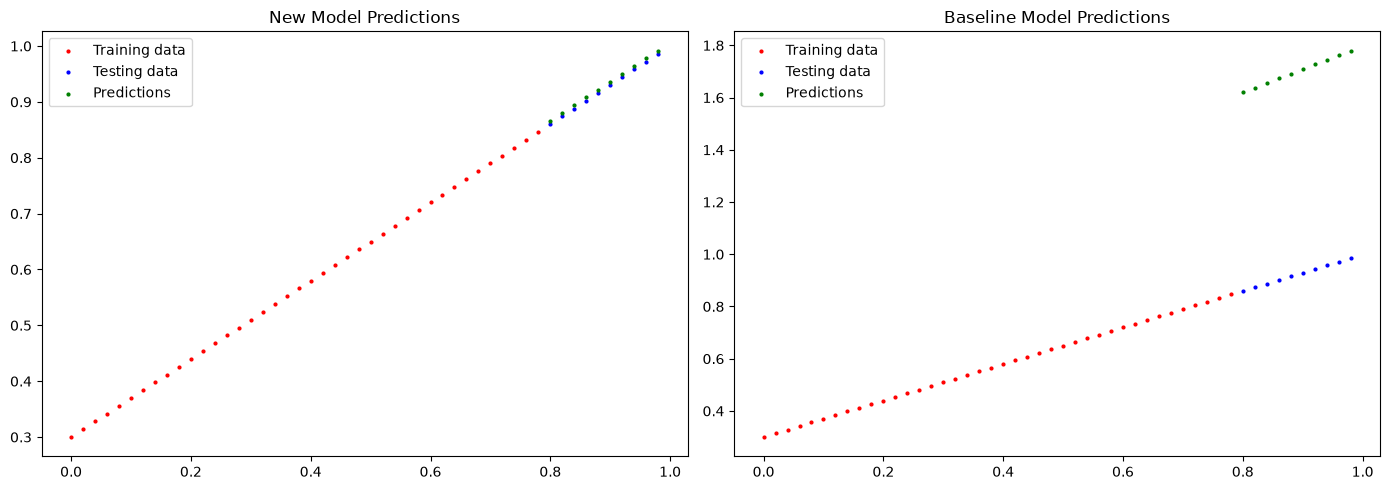

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# New model
predictions(predictions=y_new_preds, ax=axes[0])
axes[0].set_title("New Model Predictions")

# Baseline model
predictions(predictions=y_preds, ax=axes[1])
axes[1].set_title("Baseline Model Predictions")

plt.tight_layout()
plt.show()

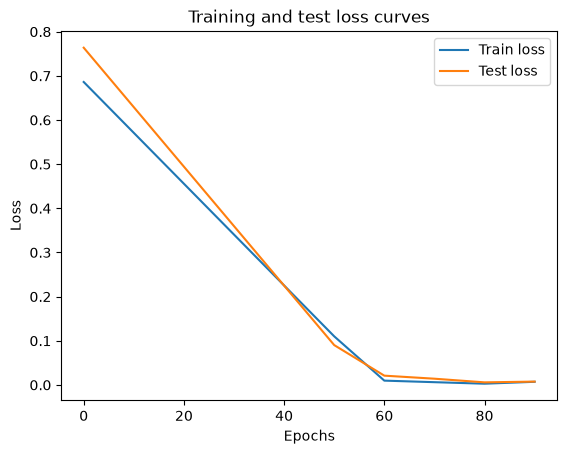

In [16]:
# Plot the loss curves
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

## Saving and Loading the Model.

There are three main methods you should about for saving and loading models in PyTorch.

1. `torch.save` --> allows you save a PyTorch object to the python pickel format.
2. `torch.load()` --> allows you load a saved PyTorch object.
3.`torch.nn.Module.load_state_dict()` --> this allows to load a model's saved state dictionary.

In [19]:
# Saving our Pytorch model 
from pathlib import Path


# Models directory

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Create model save path 

MODEL_NAME = "01_pytorch_workflow_model_0.pt"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME


# Saving the model 

print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_0.pt


In [20]:
# Loading  a PyTorch Moadels

loaded_model_0 = LinearRegression()

# 2. Load the saved model's state_dict
loaded_model_0.load_state_dict(
    torch.load(
        "models/01_pytorch_workflow_model_0.pt",
        weights_only=True
    )
)


<All keys matched successfully>

In [21]:
loaded_model_0.state_dict()

OrderedDict([('weight', tensor([0.6977])), ('bias', tensor([0.3080]))])

### Creating Model Using Pre-defined function



In [24]:
class LinearRegressionV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.Linear_Model = nn.Linear(in_features=1, 
                                      out_features=1)


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.Linear_Model(x)


torch.manual_seed(42)

model_1 = LinearRegressionV1()

model_1, model_1.state_dict() 
    


(LinearRegressionV1(
   (Linear_Model): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('Linear_Model.weight', tensor([[0.7645]])),
              ('Linear_Model.bias', tensor([0.8300]))]))

In [25]:
x_train[:5], y_train[:5]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560]]))

In [ ]:
# Set the model to use the target device 

if torch.cuda.is_available():
    device = "cuda"

else:
    device = "cpu"

In [28]:
model_1.to(device)
next(model_1.parameters()).device

device(type='cuda', index=0)

In [ ]:
loss_function = nn.L1Loss()
optimizer = optim.SGD(params=model_1.parameters(),
                      lr=0.0001)



In [ ]:
torch.manual_seed(42)

epochs = 100 

x_train = x_train.to(device)
y_train = y_train.to(device)
x_test = x_test.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
    model_1.train()

    y_preds = model_1(x_train)

    loss = loss_function(y_preds, y_train)


    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_1.eval()

    with torch.inference_mode():
        test_preds = model_1(x_test)

        loss = loss_function(test_preds)

        if epoch % 10 == 0:
            print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")